In [1]:
# Importing necessary packages and functions required
import numpy as np # for numerical computations
import pandas as pd # for data processing,I/O file operations
import matplotlib.pyplot as plt # for visualization of different kinds of plots
%matplotlib inline
# for matplotlib graphs to be included in the notebook, next to the code
import seaborn as sns # for visualization
import warnings # to silence warnings
warnings.filterwarnings('ignore')

In [3]:
# Reading the dataset
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
wine = pd.read_csv(url, sep=';')
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [5]:
# Examining the dataset
wine.shape
wine.info()
wine.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [7]:
# examing the response variable
wine['quality'].describe()

count    4898.000000
mean        5.877909
std         0.885639
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         9.000000
Name: quality, dtype: float64

<Axes: >

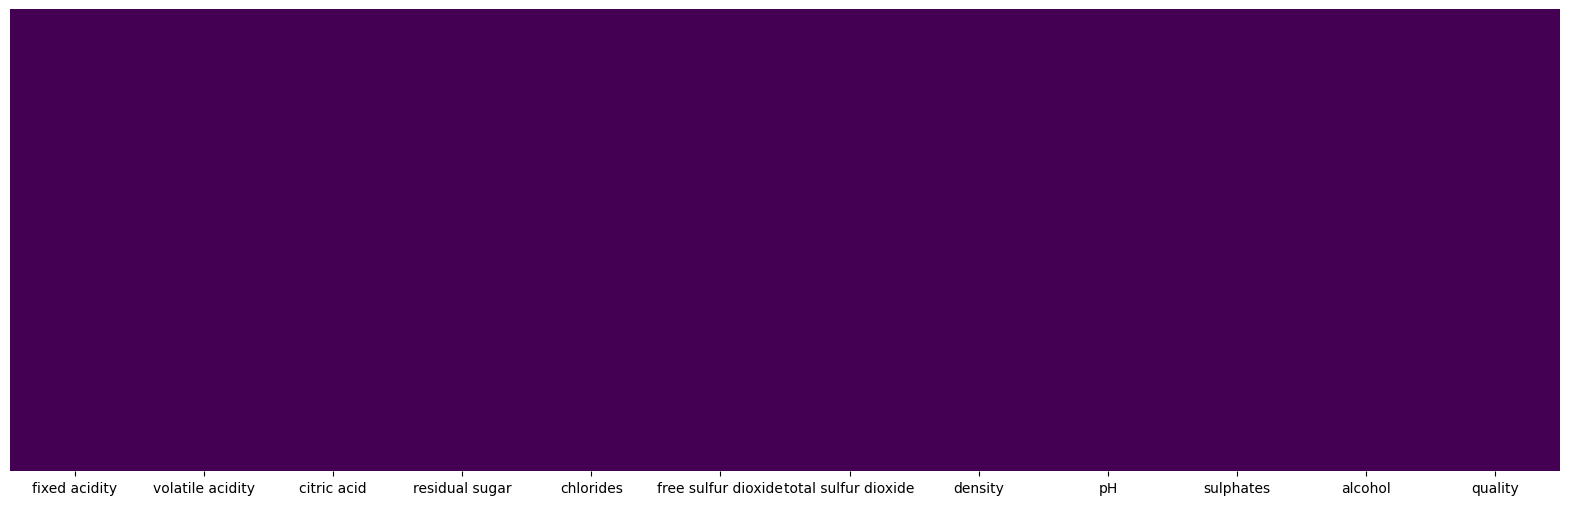

In [9]:
plt.figure(figsize=(20, 6))
sns.heatmap(wine.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [11]:
# remove rows with any missing values
wine.dropna(inplace=True)

<Axes: >

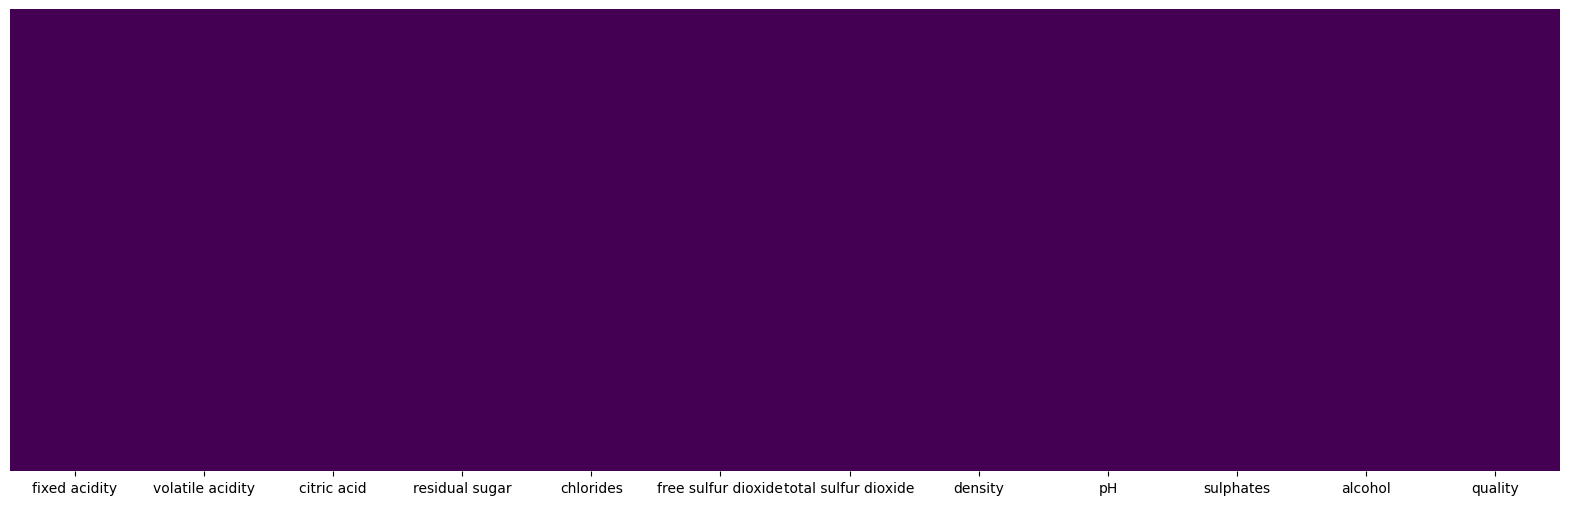

In [13]:
plt.figure(figsize=(20, 6))
sns.heatmap(wine.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [15]:
# checking the shape
wine.shape

(4898, 12)

In [17]:
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [19]:
# define X and y
X = wine.drop('quality', axis=1)
y = wine['quality']

In [21]:
# split into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

In [23]:
# standardize the features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [25]:
# build a linear regression model
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
linreg.fit(X_train, y_train)

LinearRegression()

In [27]:
print("INTERCEPT : ",linreg.intercept_)
print("CO-EFFICIENT : ",linreg.coef_)

INTERCEPT :  5.868144690781791
CO-EFFICIENT :  [ 4.21968745e-02 -2.03530845e-01  3.50581852e-04  3.99861604e-01
 -1.10964582e-02  4.97611203e-02  1.82868571e-03 -4.03213163e-01
  9.47678767e-02  6.55332098e-02  2.68393958e-01]


In [29]:
# make predictions
y_pred = linreg.predict(X_test)

In [31]:
# calculate R^2 value, MAE, MSE, RMSE
from sklearn.metrics import r2_score
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-Square Value 0.2760486987539561
mean_absolute_error : 0.5800140285670603
mean_squared_error :  0.5385307860058985
root_mean_squared_error :  0.7338465684364127


Ridge regression
* Documentación de Ridge
* alpha: debe ser positivo, aumentar para una mayor regularización
* normalizar: escala las características (sin usar StandardScaler)

In [33]:
# alpha=0 is equivalent to linear regression
from sklearn.linear_model import Ridge
ridgereg = Ridge(alpha=0)
ridgereg.fit(X_train, y_train)
y_pred = ridgereg.predict(X_test)
# calculate R^2 value, MAE, MSE, RMSE
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-Square Value 0.276048698753956
mean_absolute_error : 0.5800140285670603
mean_squared_error :  0.5385307860058985
root_mean_squared_error :  0.7338465684364127


In [35]:
# try alpha=0.1
ridgereg = Ridge(alpha=0.1)
ridgereg.fit(X_train, y_train)
y_pred = ridgereg.predict(X_test)
# calculate R^2 value, MAE, MSE, RMSE
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-Square Value 0.27604501726356034
mean_absolute_error : 0.5800147586079665
mean_squared_error :  0.5385335245822545
root_mean_squared_error :  0.7338484343393086


In [37]:
# examing the coefficients
print(ridgereg.coef_)

[ 4.20994100e-02 -2.03531838e-01  3.47082516e-04  3.99567914e-01
 -1.11181228e-02  4.97784903e-02  1.80647504e-03 -4.02785428e-01
  9.46861278e-02  6.55073298e-02  2.68569552e-01]


* RidgeCV: ridge regression con validación cruzada incorporada del parámetro alfa (LO VER
EMOS EN UN SIGUIENTE NOTEBOOK
* • alfas: matriz de valores alfa para probar

In [39]:
# create an array of alpha values
alpha_range = 10.**np.arange(-2, 3)
alpha_range

array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02])

In [41]:
# select the best alpha with RidgeCV
from sklearn.linear_model import RidgeCV

ridgeregcv = RidgeCV(
    alphas=alpha_range,
    scoring='neg_mean_squared_error'
)

ridgeregcv.fit(X_train, y_train)
ridgeregcv.alpha_

100.0

In [43]:
# predict method uses the best alpha value
y_pred = ridgeregcv.predict(X_test)
# calculate R^2 value, MAE, MSE, RMSE
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-Square Value 0.2736896397718215
mean_absolute_error : 0.5810660292240907
mean_squared_error :  0.5402856359325394
root_mean_squared_error :  0.7350412477762995


In [45]:
# Generar 200 valores de alpha
n_alphas = 200
alphas = np.logspace(-10, -2, n_alphas)

# Calcular los coeficientes para cada alpha
from sklearn.linear_model import Ridge, RidgeCV
coefs = []
for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train, y_train)
    coefs.append(ridge.coef_)
# Seleccionar el mejor alpha mediante validación cruzada
ridgeregcv_trayectoria = RidgeCV(
    alphas=alphas,
    scoring='neg_mean_squared_error',
    cv=5
)
ridgeregcv_trayectoria.fit(X_train, y_train)
# Mostrar el mejor alpha
print("Mejor alpha:", ridgeregcv_trayectoria.alpha_)
# Examinar los coeficientes
print("Coeficientes:", ridgeregcv_trayectoria.coef_)
# Predicciones Ridge
y_pred_ridge = ridgeregcv_trayectoria.predict(X_test)

print("RESULTADOS RIDGE")
print("R-Square:", r2_score(y_test, y_pred_ridge))
print("MAE:", metrics.mean_absolute_error(y_test, y_pred_ridge))
print("MSE:", metrics.mean_squared_error(y_test, y_pred_ridge))
print("RMSE:", np.sqrt(metrics.mean_squared_error(y_test, y_pred_ridge)))


Mejor alpha: 0.01
Coeficientes: [ 4.21871166e-02 -2.03530946e-01  3.50231184e-04  3.99832202e-01
 -1.10986265e-02  4.97628593e-02  1.82646245e-03 -4.03170338e-01
  9.47596922e-02  6.55306188e-02  2.68411541e-01]
RESULTADOS RIDGE
R-Square: 0.27604833063832157
MAE: 0.5800141017400582
MSE: 0.5385310598386849
RMSE: 0.733846755009985


#  Lasso regression
* Documentación de Lasso
* aalpha  deb ese rpositivo ,aumenta rpar au namayo rregularizació
* n•normalizar: esca lal ascaracterístic as(sinusarStandardScaler)

In [47]:
# try alpha=0.001 and examine coefficients
from sklearn.linear_model import Lasso
lassoreg = Lasso(alpha=0.001)
lassoreg.fit(X_train,y_train)
print(lassoreg.coef_)

[ 0.0312334  -0.20348026  0.          0.37152236 -0.01227411  0.050228
  0.         -0.36175487  0.0856707   0.06239116  0.28537042]


In [49]:
# try alpha=0.01 and examine coefficients
lassoreg = Lasso(alpha=0.01)
lassoreg.fit(X_train,y_train)
print(lassoreg.coef_)

[-0.01502863 -0.20057927 -0.          0.19875368 -0.01728887  0.04598806
 -0.         -0.12031501  0.03685751  0.03953596  0.38289142]


In [51]:
 # calculate RMSE (for alpha=0.01)
y_pred = lassoreg.predict(X_test)
# calculate MAE, MSE, RMSE
# calculate R^2 value, MAE, MSE, RMSE
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-Square Value 0.26917811049336393
mean_absolute_error : 0.583470307213972
mean_squared_error :  0.5436416591957542
root_mean_squared_error :  0.7373205945826783


In [53]:
# select the best alpha with LassoCV
from sklearn.linear_model import LassoCV
lassoregcv = LassoCV(n_alphas=100, random_state=1)
lassoregcv.fit(X_train, y_train)
print('alpha : ',lassoregcv.alpha_)
# examine the coefficients
print(lassoregcv.coef_)

alpha :  0.004145249892213636
[ 0.         -0.20358333 -0.          0.28959378 -0.01569708  0.04854878
 -0.         -0.24376555  0.05931463  0.05266009  0.33452392]


In [55]:
#predict method usesthebestalphavalue
y_pred =lassoregcv.predict(X_test)
#calculate R^2 value,MAE,MSE,RMSE
from sklearn import metrics
print("R-SquareValue",r2_score(y_test,y_pred))
print ("mean_absolute_error:",metrics.mean_absolute_error(y_test,y_pred))
print ("mean_squared_error: ",metrics.mean_squared_error(y_test,y_pred))
print ("root_mean_squared_error:",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-SquareValue 0.27301759670599424
mean_absolute_error: 0.5816713244180798
mean_squared_error:  0.5407855533715257
root_mean_squared_error: 0.7353812299559499


In [57]:
# Generar la trayectoria de alpha
from sklearn.linear_model import Lasso, LassoCV, lasso_path

eps = 5e-3

alphas_lasso, coefs_lasso, _ = lasso_path(
    X_train,
    y_train,
    eps=eps,
    max_iter=10000
)
# Seleccionar el mejor alpha mediante validación cruzada
lassoregcv_trayectoria = LassoCV(
    alphas=alphas_lasso,
    cv=5,
    max_iter=10000,
    random_state=1
)

lassoregcv_trayectoria.fit(X_train, y_train)
# Mostrar el mejor alpha
print("Mejor alpha:", lassoregcv_trayectoria.alpha_)
# Examinar los coeficientes
print("Coeficientes:", lassoregcv_trayectoria.coef_)
# Predicciones Lasso
y_pred_lasso = lassoregcv_trayectoria.predict(X_test)
print("\nRESULTADOS LASSO")
print("R-Square:", r2_score(y_test, y_pred_lasso))
print("MAE:", metrics.mean_absolute_error(y_test, y_pred_lasso))
print("MSE:", metrics.mean_squared_error(y_test, y_pred_lasso))
print("RMSE:", np.sqrt(metrics.mean_squared_error(y_test, y_pred_lasso)))

Mejor alpha: 0.0040889883379279035
Coeficientes: [ 0.         -0.20362309 -0.          0.29025128 -0.0156984   0.0485718
 -0.         -0.24461767  0.05944007  0.05276862  0.33420891]

RESULTADOS LASSO
R-Square: 0.2730303933809819
MAE: 0.5816637685918832
MSE: 0.5407760342181966
RMSE: 0.73537475766999
